# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : TANAEL STEVAN SITOHANG
- NIM   : 241011401252
- Kelas : 05TPLM003 — Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
%pip install --upgrade pip
# Install library
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 1.5 MB/s eta 0:00:07
   -- ------------------------------------- 0.8/10.9 MB 984.1 kB/s eta 0:00:11
   -- ------------------------------------- 0.8/10.9 MB 984.1 kB/s eta 0:00:11
   --- ------------------------------------ 1.0/10.9 MB 919.5 kB/s eta 0:00:11
   ---- ----------------------------------- 1.3/10.9 MB 922.0 kB/s eta 0:00:11
   ----- ---------------------------------- 1.6/10.9 MB 966.4 kB/s eta 0:00:10
   ------ --------------------------------- 1.8/10.9 MB 998.9 kB/s eta 0:00:10
   ------ --------------------------------- 1.8/10.9 MB 998.9 kB/s eta 0:00:10
   ------- -------------------------------- 2.1/10.9 MB 934.2 kB/s eta 0:00:10
   -------- ---------

In [4]:
# import Library
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 52 

In [5]:
# Implementasi train_test_split (NumPy) -- acak indeks dengan seed, lalu bagi train/test
def train_test_split(X, y, test_size=0.2, random_state=None):
    X, y = np.asarray(X), np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))            # urutan acak yang reproducible
    n_test = int(len(X) * test_size)
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


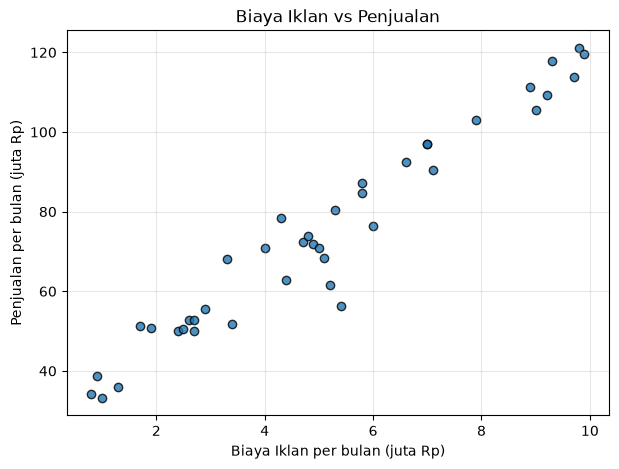

In [6]:
# Jawaban A1
# 1. Baca data, tampilkan 5 data pertama dan jumlah baris
df_ads = pd.read_csv("Ads_Data.csv")
print(df_ads.head())
print("\nJumlah baris data:", len(df_ads))

# 2. Pisahkan X (harus 2 dimensi) dan y
X = df_ads[["BiayaIklan"]].values      # shape (n, 1)
y = df_ads["Penjualan"].values         # shape (n,)
print("Shape X:", X.shape, "| Shape y:", y.shape)

# 3. Scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(X, y, color="tab:blue", edgecolor="k", alpha=0.8)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan per bulan (juta Rp)")
plt.ylabel("Penjualan per bulan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [7]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [8]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                       # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_, self.coef_ = theta[0], theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin_reg = LinearRegression().fit(X_train, y_train)
b_ne, m_ne = lin_reg.intercept_, lin_reg.coef_[0]

print(f"Intercept (b)  : {b_ne:.4f}")
print(f"Koefisien (m)  : {m_ne:.4f}")
print(f"Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X")

Intercept (b)  : 29.4375
Koefisien (m)  : 9.0091
Persamaan      : y_hat = 29.4375 + 9.0091 * X


**Jawaban A3 (interpretasi):**

Persamaan regresi yang diperoleh adalah $\hat{y} = 29{,}4375 + 9{,}0091X$.

Nilai $m = 9{,}0091$ berarti **setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan per bulan rata-rata naik sekitar 9,01 juta Rp** (selama masih dalam rentang data). Nilai intercept $b = 29{,}4375$ berarti saat biaya iklan 0, penjualan dasar toko diperkirakan sekitar 29,44 juta Rp per bulan, yaitu penjualan yang datang tanpa dorongan iklan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [9]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test  = lin_reg.predict(X_test)

hasil_eval = pd.DataFrame({
    "MAE":  [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    "MSE":  [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    "RMSE": [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    "R2":   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=["Training", "Testing"])
hasil_eval.round(4)

,MAE,MSE,RMSE,R2
Training,4.3895,28.9508,5.3806,0.9489
Testing,4.9646,67.2248,8.1991,0.9224


**Jawaban A4 (analisis):**

Pada data testing, RMSE = 8,20 (juta Rp) dan $R^2$ = 0,9224. **RMSE** berarti prediksi penjualan model rata-rata meleset sekitar 8,2 juta Rp dari nilai sebenarnya, atau sekitar 11% dari rata-rata penjualan (74,3 juta Rp). **$R^2$ = 0,92** berarti sekitar 92% variasi penjualan bisa dijelaskan oleh biaya iklan.

Pada data training RMSE-nya 5,38 dan $R^2$ = 0,9489. Performa testing sedikit lebih rendah dari training, tetapi selisihnya tidak besar sehingga tidak ada tanda overfitting yang serius. Jadi **model ini sudah cukup baik** untuk memprediksi penjualan dari biaya iklan. Catatan: data testing hanya 8 titik, jadi angkanya cukup sensitif terhadap pembagian data.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

c:\Users\ThinkPad\uts-machine-learning-241011401252\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_9284\1479184552.py:17: RuntimeWarning: overflow encountered in square
  self.loss_history_.append(np.mean(error ** 2))          # MSE
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_9284\1479184552.py:20: RuntimeWarning: overflow encountered in matmul
  self.coef_      -= self.learning_rate * 2 * (X.T @ error) / n
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_9284\1479184552.py:20: RuntimeWarning: invalid value encountered in subtract
  self.coef_      -= self.learning_rate * 2 * (X.T @ error) / n


,Intercept,Koefisien,MSE akhir (train)
Model,,,
Normal Equation,29.437523,9.009131,28.950766
GD lr=0.001,25.594983,9.611028,31.921675
GD lr=0.02,29.437523,9.009131,28.950766
GD lr=0.1,NaN,NaN,NaN


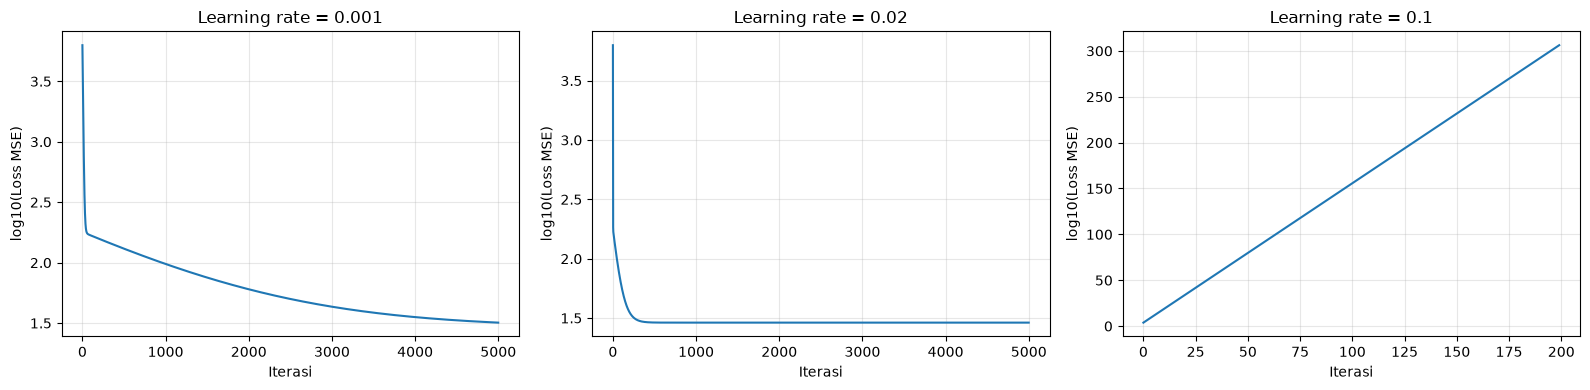

lr=0.1 -> loss iterasi ke-10  : 9.594785218220057e+18
lr=0.1 -> loss iterasi ke-100 : 5.550953897687472e+155
lr=0.1 -> iterasi pertama non-finite: 200


In [10]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)"""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history_ = []

    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            error = (self.intercept_ + X @ self.coef_) - y
            self.loss_history_.append(np.mean(error ** 2))          # MSE
            # gradient MSE terhadap b dan m
            self.intercept_ -= self.learning_rate * 2 * np.mean(error)
            self.coef_      -= self.learning_rate * 2 * (X.T @ error) / n
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
for lr in learning_rates:
    gd_models[lr] = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)

# Bandingkan dengan Normal Equation
rows = [{"Model": "Normal Equation", "Intercept": b_ne, "Koefisien": m_ne,
         "MSE akhir (train)": mse(y_train, lin_reg.predict(X_train))}]
for lr, mdl in gd_models.items():
    rows.append({"Model": f"GD lr={lr}", "Intercept": mdl.intercept_,
                 "Koefisien": mdl.coef_[0], "MSE akhir (train)": mdl.loss_history_[-1]})
display(pd.DataFrame(rows).set_index("Model"))

# Grafik loss vs iterasi (skala log10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(gd_models[lr].loss_history_)
    loss = np.where(np.isfinite(loss), loss, np.nan)    # inf/nan tidak digambar
    ax.plot(np.log10(loss))                             # log10 manual: nilai 1e155 tetap bisa digambar
    ax.set_title(f"Learning rate = {lr}")
    ax.set_xlabel("Iterasi"); ax.set_ylabel("log10(Loss MSE)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Iterasi saat loss lr=0.1 meledak menjadi inf/nan
loss_besar = np.array(gd_models[0.1].loss_history_)
print("lr=0.1 -> loss iterasi ke-10  :", loss_besar[10])
print("lr=0.1 -> loss iterasi ke-100 :", loss_besar[100])
print("lr=0.1 -> iterasi pertama non-finite:", int(np.argmax(~np.isfinite(loss_besar))))

**Jawaban A5 (analisis):**

Hasil untuk ketiga learning rate:

- **lr = 0,001 (terlalu lambat).** Setelah 5000 iterasi parameternya baru $b$ = 25,59 dan $m$ = 9,61, masih berbeda dari normal equation ($b$ = 29,44; $m$ = 9,01). MSE akhir 31,92 masih di atas MSE optimum 28,95. Langkah update terlalu kecil sehingga 5000 iterasi belum cukup untuk konvergen.
- **lr = 0,02 (pas).** Loss turun cepat lalu stabil, dan parameter akhirnya identik dengan normal equation ($b$ = 29,4375; $m$ = 9,0091). Ini menunjukkan GD dan normal equation menuju solusi optimum yang sama.
- **lr = 0,1 (divergen).** Loss tidak turun, malah membesar eksponensial (sekitar $10^{155}$ pada iterasi ke-100), lalu menjadi `inf` dan `nan` mulai sekitar iterasi ke-200, sehingga parameter akhir juga `nan`. Langkah update terlalu besar sehingga setiap iterasi melompati titik minimum dan mendarat lebih jauh dari sebelumnya. Secara teori, GD stabil jika $lr < 2/\lambda_{max}$ dari Hessian loss. Di data ini batasnya sekitar 0,03, sehingga 0,02 aman tetapi 0,1 pasti melampaui batas.

`RuntimeWarning: overflow` berarti nilai yang dihitung sudah melebihi batas terbesar float64 (sekitar $10^{308}$). Itu adalah tanda bahwa GD divergen, bukan bug pada kode.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

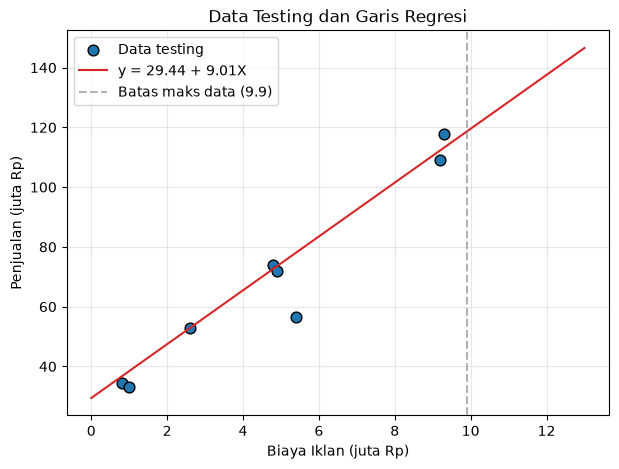

Rentang BiayaIklan pada data: 0.8 - 9.9 juta Rp

Biaya iklan  4.5 juta -> prediksi penjualan 69.98 juta Rp (interpolasi)
Biaya iklan  7.0 juta -> prediksi penjualan 92.50 juta Rp (interpolasi)
Biaya iklan 12.0 juta -> prediksi penjualan 137.55 juta Rp (ekstrapolasi)


In [11]:
# Jawaban A6
# 1. Scatter data testing + garis regresi (model Normal Equation)
x_garis = np.linspace(0, 13, 100).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color="tab:blue", edgecolor="k", s=60, label="Data testing")
plt.plot(x_garis, lin_reg.predict(x_garis), color="tab:red",
         label=f"y = {b_ne:.2f} + {m_ne:.2f}X")
plt.axvline(X.max(), color="gray", linestyle="--", alpha=0.6, label="Batas maks data (9.9)")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi untuk biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi = lin_reg.predict(biaya_baru)
print(f"Rentang BiayaIklan pada data: {X.min()} - {X.max()} juta Rp\n")
for biaya, p in zip(biaya_baru.ravel(), prediksi):
    ket = "(ekstrapolasi)" if biaya > X.max() else "(interpolasi)"
    print(f"Biaya iklan {biaya:>4} juta -> prediksi penjualan {p:.2f} juta Rp {ket}")

**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4,5 juta menghasilkan 69,98 juta Rp, 7 juta menghasilkan 92,50 juta Rp, dan 12 juta menghasilkan 137,55 juta Rp.

Prediksi untuk 4,5 dan 7 juta berada di dalam rentang data (0,8 sampai 9,9 juta) sehingga cukup bisa dipercaya. Prediksi untuk 12 juta adalah **ekstrapolasi** dan **kurang bisa dipercaya**: model hanya belajar dari data sampai 9,9 juta, dan tidak ada bukti bahwa hubungan linear tetap berlaku di luar rentang itu. Dalam praktik, efek iklan sering mengalami *diminishing returns* (kenaikan penjualan makin kecil saat biaya makin besar) atau terbentur batas pasar, sehingga penjualan sebenarnya bisa jauh lebih rendah dari 137,55 juta.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah email Spam (1)       : 25
Jumlah email Bukan Spam (0) : 35

Shape X: (60, 2) | Shape y: (60,)


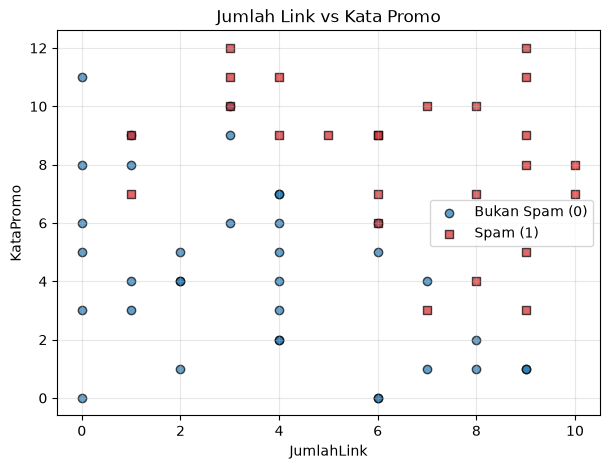

In [12]:
# Jawaban B1
# 1. Baca data, 5 data pertama, dan jumlah kelas
df_email = pd.read_csv("Email_Data.csv")
print(df_email.head())
print("\nJumlah email Spam (1)       :", (df_email["Spam"] == 1).sum())
print("Jumlah email Bukan Spam (0) :", (df_email["Spam"] == 0).sum())

# 2. Pisahkan fitur dan label
Xe = df_email[["JumlahLink", "KataPromo"]].values.astype(float)   # shape (n, 2)
ye = df_email["Spam"].values                                      # shape (n,)
print("\nShape X:", Xe.shape, "| Shape y:", ye.shape)

# 3. Scatter plot per kelas
plt.figure(figsize=(7, 5))
plt.scatter(Xe[ye == 0, 0], Xe[ye == 0, 1], c="tab:blue", edgecolor="k", alpha=0.7, label="Bukan Spam (0)")
plt.scatter(Xe[ye == 1, 0], Xe[ye == 1, 1], c="tab:red", marker="s", edgecolor="k", alpha=0.7, label="Spam (1)")
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Train: (45, 2) | Test: (15, 2)

Intercept (b) : -11.0478
Koefisien m1  : 0.9466  (JumlahLink)
Koefisien m2  : 0.9278  (KataPromo)
P(Spam) = sigmoid(-11.0478 + 0.9466*JumlahLink + 0.9278*KataPromo)


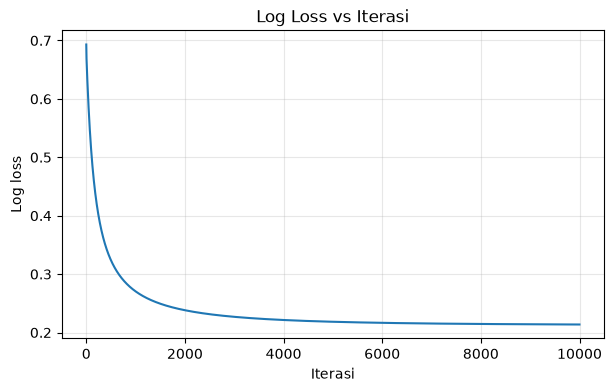

Loss awal: 0.6931 | iterasi 1000: 0.2704 | iterasi 9000: 0.2141 | akhir: 0.2137


In [13]:
# Jawaban B2
# 1. Split data
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    Xe, ye, test_size=0.25, random_state=RANDOM_STATE)
print("Train:", Xe_train.shape, "| Test:", Xe_test.shape)

# 2. Logistic Regression dengan Gradient Descent
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history_ = []

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))      # clip supaya exp tidak overflow

    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.loss_history_ = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = self._sigmoid(self.intercept_ + X @ self.coef_)
            pc = np.clip(p, eps, 1 - eps)
            self.loss_history_.append(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc)))  # log loss
            error = p - y
            self.intercept_ -= self.learning_rate * np.mean(error)
            self.coef_      -= self.learning_rate * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return self._sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)

# 3. Parameter dan persamaan
b_lr, (m1, m2) = log_reg.intercept_, log_reg.coef_
print(f"\nIntercept (b) : {b_lr:.4f}")
print(f"Koefisien m1  : {m1:.4f}  (JumlahLink)")
print(f"Koefisien m2  : {m2:.4f}  (KataPromo)")
print(f"P(Spam) = sigmoid({b_lr:.4f} + {m1:.4f}*JumlahLink + {m2:.4f}*KataPromo)")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(7, 4))
plt.plot(log_reg.loss_history_)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi"); plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()
print(f"Loss awal: {log_reg.loss_history_[0]:.4f} | iterasi 1000: {log_reg.loss_history_[1000]:.4f} | "
      f"iterasi 9000: {log_reg.loss_history_[9000]:.4f} | akhir: {log_reg.loss_history_[-1]:.4f}")

**Jawaban B2 (analisis):**

Persamaan yang diperoleh: $P(\text{Spam}) = \sigma(-11{,}0478 + 0{,}9466 \cdot \text{JumlahLink} + 0{,}9278 \cdot \text{KataPromo})$.

Kedua koefisien bernilai positif: semakin banyak link dan kata promosi, semakin besar peluang email dianggap spam. Setiap tambahan satu link menaikkan *odds* spam sekitar 2,58 kali ($e^{0{,}9466}$) dan setiap tambahan satu kata promosi sekitar 2,53 kali ($e^{0{,}9278}$), dengan variabel lain tetap.

Loss turun dari 0,6931 (tebakan acak, $\ln 2$) menjadi 0,2137. Penurunannya cepat di awal (0,27 pada iterasi 1000) lalu melandai. Dari iterasi 9000 ke 10000 loss hanya turun sekitar 0,0004, jadi sudah **turun dan hampir stabil**.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [14]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Return [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred_test = log_reg.predict(Xe_test)          # threshold default 0.5

print(f"Accuracy  : {accuracy_score(ye_test, ye_pred_test):.4f}")
print(f"Precision : {precision_score(ye_test, ye_pred_test):.4f}")
print(f"Recall    : {recall_score(ye_test, ye_pred_test):.4f}")
print(f"F1-score  : {f1_score(ye_test, ye_pred_test):.4f}")

cm = confusion_matrix(ye_test, ye_pred_test)
display(pd.DataFrame(cm,
                     index=["Aktual: Bukan Spam", "Aktual: Spam"],
                     columns=["Prediksi: Bukan Spam", "Prediksi: Spam"]))

Accuracy  : 0.8667
Precision : 0.8750
Recall    : 0.8750
F1-score  : 0.8750


,Prediksi: Bukan Spam,Prediksi: Spam
Aktual: Bukan Spam,6,1
Aktual: Spam,1,7


**Jawaban B3 (analisis):**

Pada data testing (15 email), accuracy = 0,8667 (13 dari 15 benar). Confusion matrix: TN = 6, FP = 1, FN = 1, TP = 7, sehingga precision = recall = F1 = 0,875.

- **FP (false positive):** email asli (bukan spam) yang salah diklasifikasikan sebagai spam.
- **FN (false negative):** email spam yang lolos dan dianggap bukan spam.

Menurut saya **FP lebih merugikan pengguna**. Email penting seperti tagihan, undangan wawancara, atau notifikasi akun bisa masuk folder spam dan tidak terbaca, dan kerugiannya bisa besar. FN hanya membuat satu email spam muncul di inbox, yang mengganggu tetapi mudah dihapus.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = 11.9071 + (-1.0203) * x1


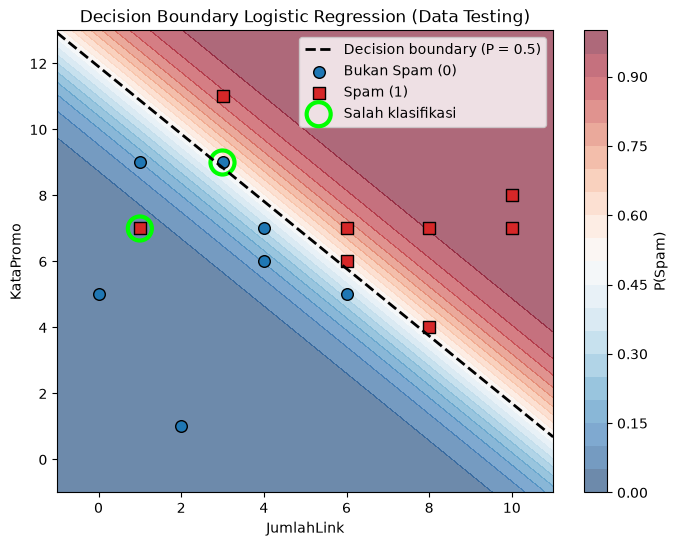

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Label asli,Prediksi,P(Spam)
0,1.0,7.0,1,0,0.0264
1,3.0,9.0,0,1,0.5356


In [15]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
intercept_garis = -b_lr / m2
slope_garis = -m1 / m2
print(f"Decision boundary: x2 = {intercept_garis:.4f} + ({slope_garis:.4f}) * x1")

# 2. Visualisasi data testing + background probabilitas + garis boundary
xx1, xx2 = np.meshgrid(np.linspace(-1, 11, 300), np.linspace(-1, 13, 300))
grid = np.c_[xx1.ravel(), xx2.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(xx1.shape)

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, prob_grid, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")
x1_line = np.linspace(-1, 11, 100)
plt.plot(x1_line, intercept_garis + slope_garis * x1_line, "k--", linewidth=2, label="Decision boundary (P = 0.5)")

plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], c="tab:blue", edgecolor="k", s=70, label="Bukan Spam (0)")
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], c="tab:red", marker="s", edgecolor="k", s=70, label="Spam (1)")

# 3. Tandai data testing yang salah diklasifikasikan
salah = ye_pred_test != ye_test
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=300, facecolors="none", edgecolors="lime", linewidths=3, label="Salah klasifikasi")

plt.xlim(-1, 11); plt.ylim(-1, 13)
plt.title("Decision Boundary Logistic Regression (Data Testing)")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="upper right"); plt.show()

df_salah = pd.DataFrame({
    "JumlahLink": Xe_test[salah, 0], "KataPromo": Xe_test[salah, 1],
    "Label asli": ye_test[salah], "Prediksi": ye_pred_test[salah],
    "P(Spam)": log_reg.predict_proba(Xe_test[salah]).round(4)})
print("Data testing yang salah diklasifikasikan:")
display(df_salah)

**Jawaban B4 (analisis):**

Persamaan decision boundary: $x_2 = 11{,}9071 - 1{,}0203\,x_1$. Email di atas/kanan garis diprediksi spam, sedangkan di bawah/kiri garis diprediksi bukan spam.

Ada **2 data testing yang salah diklasifikasikan** (ditandai lingkaran hijau pada grafik):

1. Email dengan JumlahLink = 1 dan KataPromo = 7 berlabel **spam** tetapi diprediksi bukan spam (P = 0,026). Ini FN. Email ini punya sedikit link sehingga model menganggapnya aman.
2. Email dengan JumlahLink = 3 dan KataPromo = 9 berlabel **bukan spam** tetapi diprediksi spam (P = 0,536). Ini FP. Posisinya sangat dekat dengan garis batas.

Keduanya berada di daerah yang bertumpang tindih antar kelas, sehingga model linear tidak bisa memisahkannya dengan sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [16]:
# Jawaban B5
proba_test = log_reg.predict_proba(Xe_test)

rows = []
for t in [0.3, 0.5, 0.7]:
    y_pred_t = (proba_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(ye_test, y_pred_t).ravel()
    rows.append({"Threshold": t, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "Precision": precision_score(ye_test, y_pred_t),
                 "Recall": recall_score(ye_test, y_pred_t),
                 "Accuracy": accuracy_score(ye_test, y_pred_t)})
tabel_threshold = pd.DataFrame(rows).set_index("Threshold")
tabel_threshold.round(4)

,TN,FP,FN,TP,Precision,Recall,Accuracy
Threshold,,,,,,,
0.3,4,3,1,7,0.700,0.875,0.7333
0.5,6,1,1,7,0.875,0.875,0.8667
0.7,7,0,3,5,1.000,0.625,0.8000


**Jawaban B5 (analisis):**

Hasil pada data testing:

| Threshold | TN | FP | FN | TP | Precision | Recall |
|---|---|---|---|---|---|---|
| 0,3 | 4 | 3 | 1 | 7 | 0,700 | 0,875 |
| 0,5 | 6 | 1 | 1 | 7 | 0,875 | 0,875 |
| 0,7 | 7 | 0 | 3 | 5 | 1,000 | 0,625 |

**Menaikkan threshold** membuat model lebih ketat dalam memberi label spam. FP berkurang sehingga *precision naik* (0,70 menjadi 1,00), tetapi lebih banyak spam lolos (FN naik) sehingga *recall turun* (0,875 menjadi 0,625). **Menurunkan threshold** berlaku sebaliknya: recall tinggi, tetapi lebih banyak email asli salah diblokir (precision turun).

Sesuai jawaban B3 bahwa FP lebih merugikan, saya memilih **threshold 0,7**. Pada threshold ini tidak ada email asli yang salah masuk spam (precision = 1,0). Konsekuensinya, 3 dari 8 spam lolos ke inbox, tetapi itu risiko yang lebih bisa diterima. Perlu dicatat data testing hanya 15 email, sehingga pemilihan ini sebaiknya dikonfirmasi dengan data yang lebih banyak.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [17]:
# Jawaban B6
THRESHOLD = 0.7      # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"],
                           "JumlahLink": [1, 5, 9, 2],
                           "KataPromo": [2, 6, 10, 11]})
proba_baru = log_reg.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values.astype(float))

email_baru["P(Spam)"] = proba_baru.round(4)
email_baru["Prediksi"] = np.where(proba_baru >= THRESHOLD, "Spam", "Bukan Spam")
email_baru

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0003,Bukan Spam
1,E2,5,6,0.3213,Bukan Spam
2,E3,9,10,0.9988,Spam
3,E4,2,11,0.7411,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena targetnya adalah kelas diskrit (spam atau bukan spam), bukan nilai kontinu. Nama "regression" berasal dari model yang pertama-tama menghitung kombinasi linear $z = b + m_1x_1 + m_2x_2$ seperti regresi linear. Fungsi sigmoid $\sigma(z) = 1/(1+e^{-z})$ lalu mengubah $z$ yang rentangnya tak terbatas menjadi probabilitas antara 0 dan 1. Probabilitas ini kemudian dibandingkan dengan threshold (misalnya 0,5) untuk menentukan kelas akhirnya.

**Jawaban C2:**
Normal equation menghitung parameter optimum langsung dalam satu rumus, $\theta = (X^TX)^{-1}X^Ty$, tanpa learning rate dan iterasi. Gradient descent mencari parameter secara bertahap dengan menurunkan loss mengikuti gradiennya, dan hasilnya bergantung pada learning rate serta jumlah iterasi (seperti terlihat di Soal A5). Gradient descent sebaiknya dipakai ketika jumlah fitur atau data sangat besar, karena normal equation harus membalik matriks $X^TX$ yang mahal secara komputasi (sekitar $O(d^3)$). Gradient descent juga bisa dipakai pada model yang tidak punya solusi langsung, seperti Logistic Regression dan neural network.

**Jawaban C3:**
Model harus dievaluasi pada data testing karena data training sudah dilihat model saat belajar, sehingga skor di training tidak menunjukkan kemampuan model pada data baru. Data testing mensimulasikan data nyata yang belum pernah dilihat. Overfitting adalah kondisi ketika model terlalu "menghafal" data training, termasuk noise-nya, sehingga skor training sangat bagus tetapi skor testing jauh lebih buruk. Pada tugas ini RMSE training (5,38) dan testing (8,20) cukup dekat, jadi overfitting-nya tidak parah.

**Jawaban C4:**
Output Linear Regression adalah nilai kontinu, dan MSE yang mengukur kuadrat selisih nilai prediksi dan nilai asli cocok untuk itu. Output Logistic Regression adalah probabilitas kelas. Jika MSE dipakai dengan sigmoid, fungsi loss-nya menjadi non-convex sehingga gradient descent bisa terjebak di minimum lokal, dan gradiennya mengecil saat prediksi salah tetapi sangat yakin. Log loss $-[y\ln p + (1-y)\ln(1-p)]$ berasal dari prinsip *maximum likelihood* untuk data biner, bersifat convex untuk Logistic Regression, dan memberi penalti sangat besar pada prediksi yang yakin tetapi salah.

**Jawaban C5:**
Pembagian data train/test diacak berdasarkan `random_state` yang berasal dari NIM masing-masing, sehingga data yang masuk training dan testing berbeda untuk setiap mahasiswa. Akibatnya koefisien, error, dan akurasi yang dihasilkan juga berbeda walau dataset dan algoritmanya sama. Dengan data testing yang kecil (8 dan 15 titik), satu data saja yang pindah ke testing bisa mengubah akurasi cukup jauh. Perbedaan juga bisa muncul dari pengaturan lain seperti nilai awal parameter, learning rate, dan jumlah iterasi.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [18]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression: data training yang sama (Bagian A) ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
print("=== Linear Regression ===")
display(pd.DataFrame({
    "Intercept": [b_ne, sk_lin.intercept_],
    "Koefisien": [m_ne, sk_lin.coef_[0]],
    "R2 test":   [r2_score(y_test, lin_reg.predict(X_test)), r2_score(y_test, sk_lin.predict(X_test))],
    "RMSE test": [rmse(y_test, lin_reg.predict(X_test)), rmse(y_test, sk_lin.predict(X_test))],
}, index=["Implementasi sendiri", "scikit-learn"]).round(4))

# --- Logistic Regression: data training yang sama (Bagian B) ---
sk_log_default = SkLogisticRegression(max_iter=10000).fit(Xe_train, ye_train)          # default: L2, C=1.0
sk_log_noreg   = SkLogisticRegression(C=1e10, max_iter=10000).fit(Xe_train, ye_train)  # regularisasi hampir dimatikan

def ringkas(nama, b, w, y_pred):
    return {"Model": nama, "Intercept": b, "m1 (Link)": w[0], "m2 (Promo)": w[1],
            "Accuracy test": accuracy_score(ye_test, y_pred),
            "F1 test": f1_score(ye_test, y_pred)}

print("\n=== Logistic Regression ===")
display(pd.DataFrame([
    ringkas("Implementasi sendiri (GD, tanpa regularisasi)", b_lr, log_reg.coef_, log_reg.predict(Xe_test)),
    ringkas("sklearn default (C=1, L2)", sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(Xe_test)),
    ringkas("sklearn C=1e10 (hampir tanpa regularisasi)", sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(Xe_test)),
]).set_index("Model").round(4))

=== Linear Regression ===


,Intercept,Koefisien,R2 test,RMSE test
Implementasi sendiri,29.4375,9.0091,0.9224,8.1991
scikit-learn,29.4375,9.0091,0.9224,8.1991



=== Logistic Regression ===


,Intercept,m1 (Link),m2 (Promo),Accuracy test,F1 test
Model,,,,,
"Implementasi sendiri (GD, tanpa regularisasi)",-11.0478,0.9466,0.9278,0.8667,0.875
"sklearn default (C=1, L2)",-10.2558,0.8670,0.8636,0.8667,0.875
sklearn C=1e10 (hampir tanpa regularisasi),-12.1996,1.0545,1.0179,0.8667,0.875


**Jawaban Bonus (analisis):**

**Linear Regression:** koefisien, intercept, dan metrik evaluasi scikit-learn **identik** dengan implementasi saya, karena keduanya menyelesaikan masalah *least squares* yang sama dengan solusi tertutup.

**Logistic Regression:** koefisien scikit-learn **berbeda**. Dengan pengaturan default, hasilnya $b$ = -10,26 dan $m$ = (0,867; 0,864), lebih kecil daripada milik saya ($b$ = -11,05; $m$ = 0,947; 0,928). Penyebabnya, `LogisticRegression` scikit-learn secara default memakai **regularisasi L2 dengan C = 1,0** yang menambahkan penalti pada besar koefisien sehingga koefisien menyusut ("shrinkage"). Implementasi saya tidak memakai regularisasi.

Saat regularisasi hampir dimatikan (C = 1e10), koefisien scikit-learn justru lebih besar ($b$ = -12,20; $m$ = 1,055; 1,018) daripada milik saya. Hal ini terjadi karena data hampir terpisah secara linear, sehingga tanpa regularisasi koefisien optimum cenderung terus membesar, dan gradient descent saya berhenti pada iterasi ke-10000 (loss masih turun sangat pelan), sementara solver scikit-learn (lbfgs) berjalan sampai konvergen.

Walaupun koefisiennya berbeda, **akurasi pada data testing sama** (0,8667) pada ketiga model, karena arah dan posisi decision boundary-nya mirip.